# 01. Бустинговые классификаторы GoA: обучение и оценка

## Вопрос и методика перед обучением

Задача – обучение с учителем, **бинарная классификация GoA на C40**.
Метод – CatBoostClassifier: градиентный бустинг деревьев с Logloss.
Прогноз – вероятность класса 1 по исходной разметке. Сравниваем варианты
без погоды (8 полей) и с погодой (34 поля) на одинаковых событиях.

Train 2019–2021: обучение категориальных преобразований и деревьев.
Validation 2022: выбор по AP и пороги. Test 2023: оценка после фиксации
выбора обоих вариантов. Test уже использовался прежде; оценка исследовательская.
Идентификаторы, полоса, число попыток и будущие исходы не являются признаками.
Историческая доступность условна, практическая пригодность не подтверждена.

Источник API: [официальная документация CatBoostClassifier](https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier)
и [fit](https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier_fit).


In [1]:
from pathlib import Path
import sys,json,hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd();BASE=ROOT/'research/boosting-weather-comparison'
sys.path.insert(0,str(ROOT/'src'));sys.path.insert(0,str(BASE/'scripts'))
from boosting_experiment import Experiment,CONFIG,DEST,write_json
from approach_risk.evaluation.classification import metrics
from approach_risk.evaluation.bootstrap import paired_intervals
experiment=Experiment()
display(pd.DataFrame([{'parameter':k,'value':str(v)} for k,v in CONFIG['parameters'].items()]))
display(json.loads((BASE/'reports/01_environment.json').read_text()))


,parameter,value
0,loss_function,Logloss
1,iterations,500
2,depth,6
3,learning_rate,0.05
4,l2_leaf_reg,3
5,random_seed,20261011
6,thread_count,6
7,bootstrap_type,No
8,has_time,True
9,task_type,CPU


{'versions': {'catboost': '1.2.10',
  'numpy': '2.5.3',
  'pandas': '3.0.6',
  'pyarrow': '25.0.1',
  'scikit-learn': '1.9.1',
  'nbformat': '5.11.1',
  'nbclient': '0.11.0'},
 'fingerprint': 'ca87eaf6b653ff7b87f424efa75cfba7e4baddc847d338681b468d72470380ea',
 'task': 'supervised binary classification',
 'family': 'CatBoostClassifier',
 'dataset_manifest_sha256': '610d45bcb1ceb9112c1e32531ac9f95c32ccc628399ea8cec9245ed4ad8f97b5'}

## 1. Обучение непогодных классификаторов

Методика: бинарная классификация CatBoost, fit **только train**, без eval_set,
early stopping, весов классов и подвыборки. 500 деревьев каждого кандидата.
Фиксированный вариант depth=6, lr=0.05; четыре кандидата depth=4/8 × lr=0.03/0.1.
Числовые пропуски NaN, категориальные – отдельный код. CatBoost сохраняет
хронологический порядок train. Validation используется после каждого fit.
Метрики train описывают оптимизацию, а не обобщающую способность.


In [2]:
baseline_candidates=experiment.train_variant('baseline',False)
display(baseline_candidates[['candidate','depth','learning_rate','AP','ROC_AUC','Brier','seconds']])

baseline: train=4165060, validation=1619848, predictors=8


Before fit: supervised binary classification GoA, CatBoost Logloss; baseline/fixed; train only, no eval_set.


0:	learn: 0.5579712	total: 731ms	remaining: 6m 4s


50:	learn: 0.0193792	total: 24.7s	remaining: 3m 37s


100:	learn: 0.0190037	total: 48.4s	remaining: 3m 11s


...

400:	learn: 0.0183545	total: 4m 11s	remaining: 1m 1s


450:	learn: 0.0183070	total: 4m 43s	remaining: 30.8s


499:	learn: 0.0182591	total: 5m 15s	remaining: 0us


Validation: baseline d8_lr0.1 0.0047134671930466505 0.5927983256553837


,candidate,depth,learning_rate,AP,ROC_AUC,Brier,seconds
0,fixed,6,0.05,0.004478,0.598169,0.003066,250.076135
1,d4_lr0.03,4,0.03,0.004191,0.590406,0.003067,174.755188
2,d4_lr0.1,4,0.10,0.004595,0.596237,0.003066,183.553060
3,d8_lr0.03,8,0.03,0.004365,0.596279,0.003066,281.676069
4,d8_lr0.1,8,0.10,0.004713,0.592798,0.003066,318.981890


## 2. Обучение погодных классификаторов

Методика: та же бинарная классификация CatBoost и тот же бюджет из пяти
конфигураций. Используются одинаковые train/validation события, добавляются
только 26 принятых погодных полей. Данные не фильтруются по наличию погоды.
Флаги источника, давность и COR не входят в предикторы. Test еще не оценивается.


In [3]:
weather_candidates=experiment.train_variant('weather',True)
display(weather_candidates[['candidate','depth','learning_rate','AP','ROC_AUC','Brier','seconds']])

weather: train=4165060, validation=1619848, predictors=34


Before fit: supervised binary classification GoA, CatBoost Logloss; weather/fixed; train only, no eval_set.


0:	learn: 0.5565869	total: 1.52s	remaining: 12m 39s


50:	learn: 0.0191304	total: 1m 5s	remaining: 9m 35s


100:	learn: 0.0187248	total: 2m 11s	remaining: 8m 38s


...

400:	learn: 0.0180600	total: 12m 15s	remaining: 3m 1s


450:	learn: 0.0179903	total: 13m 50s	remaining: 1m 30s


499:	learn: 0.0179345	total: 15m 20s	remaining: 0us


Validation: weather d8_lr0.1 0.008257842536102828 0.6514957503584835


,candidate,depth,learning_rate,AP,ROC_AUC,Brier,seconds
0,fixed,6,0.05,0.008368,0.645041,0.003062,680.716274
1,d4_lr0.03,4,0.03,0.008549,0.637842,0.003061,445.687995
2,d4_lr0.1,4,0.10,0.008772,0.646435,0.003061,449.883429
3,d8_lr0.03,8,0.03,0.008394,0.644545,0.003062,860.576574
4,d8_lr0.1,8,0.10,0.008258,0.651496,0.003062,925.934475


## 3. Фиксация выбора по validation

Выбираем максимальный AP отдельно внутри каждого варианта. При равенстве –
меньшую глубину, затем learning_rate. Поиск не расширяется по test.
Выбранные конфигурации сохраняются до вызова оценки test.


,variant,candidate,depth,learning_rate,AP,ROC_AUC
0,baseline,d8_lr0.1,8,0.1,0.004713,0.592798
1,weather,d4_lr0.1,4,0.1,0.008772,0.646435


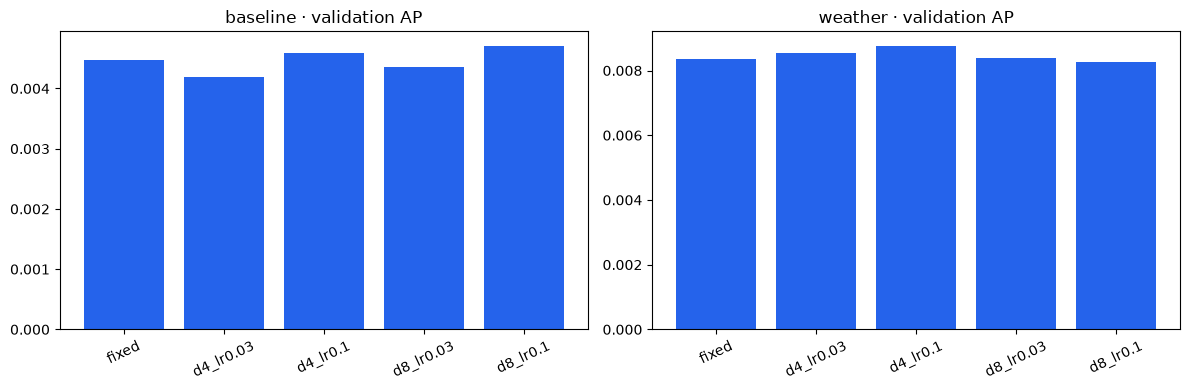

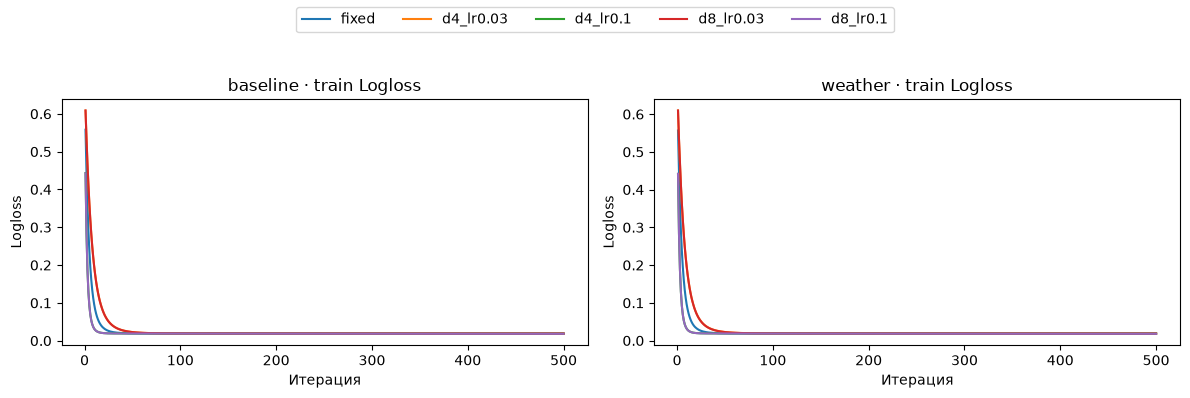

In [4]:
selected=experiment.select();display(selected[['variant','candidate','depth','learning_rate','AP','ROC_AUC']])
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,name in zip(axes,['baseline','weather']):
    f=pd.DataFrame([x for x in experiment.rows if x['variant']==name])
    ax.bar(f.candidate,f.AP,color='#2563eb');ax.set_title(name+' · validation AP');ax.tick_params(axis='x',rotation=25)
fig.tight_layout()
for ext in ['png','svg']:fig.savefig(BASE/f'figures/01_validation_candidates.{ext}',dpi=160,bbox_inches='tight')
plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,name in zip(axes,['baseline','weather']):
    for candidate,_,_ in experiment.candidates:
        f=pd.read_csv(BASE/f'reports/01_{name}_{candidate}_learning.csv')
        ax.plot(f.iteration,f.train_Logloss,label=candidate)
    ax.set_title(name+' · train Logloss');ax.set_xlabel('Итерация');ax.set_ylabel('Logloss')
handles,labels=axes[0].get_legend_handles_labels()
fig.legend(handles,labels,loc='upper center',ncol=5);fig.tight_layout(rect=(0,0,1,.85))
for ext in ['png','svg']:fig.savefig(BASE/f'figures/02_learning_curves.{ext}',dpi=160,bbox_inches='tight')
plt.show()


## 4. Оценка зафиксированной пары на test

Методика оценки классификации: AP, ROC-AUC, Brier и калибровка. Пороги
максимальной полноты при FPR<=0.1%, 0.5%, 1% выбираются только validation.
На test пороги не меняются, показываются фактическая FPR и полнота.
Включены срезы по аэропортам, месяцам и покрытию погоды. Логистический
baseline сравнивается на тех же событиях, без повторного обучения.


,dimension,group,model,rows,GoA,AP,ROC_AUC,Brier,target_validation_FPR,TP,FP,FN,TN,recall,FPR,precision
0,all,all,baseline,546577,1739,0.004361,0.571119,0.003172,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,all,all,baseline,546577,1739,NaN,NaN,NaN,0.001,11.0,1379.0,1728.0,543459.0,0.006325,0.002531,0.007914
2,all,all,baseline,546577,1739,NaN,NaN,NaN,0.005,38.0,6163.0,1701.0,538675.0,0.021852,0.011312,0.006128
3,all,all,baseline,546577,1739,NaN,NaN,NaN,0.010,87.0,12088.0,1652.0,532750.0,0.050029,0.022186,0.007146
4,all,all,weather,546577,1739,0.006812,0.623655,0.003168,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,all,all,weather,546577,1739,NaN,NaN,NaN,0.001,15.0,565.0,1724.0,544273.0,0.008626,0.001037,0.025862
6,all,all,weather,546577,1739,NaN,NaN,NaN,0.005,65.0,3454.0,1674.0,541384.0,0.037378,0.006339,0.018471
7,all,all,weather,546577,1739,NaN,NaN,NaN,0.010,117.0,7150.0,1622.0,537688.0,0.067280,0.013123,0.016100


,family,variant,rows,GoA,AP,ROC_AUC,Brier
0,CatBoost,baseline,546577,1739,0.004361,0.571119,0.003172
1,Logistic,baseline,546577,1739,0.003989,0.568153,0.003171
2,CatBoost,weather,546577,1739,0.006812,0.623655,0.003168
3,Logistic,weather,546577,1739,0.006679,0.608395,0.003168


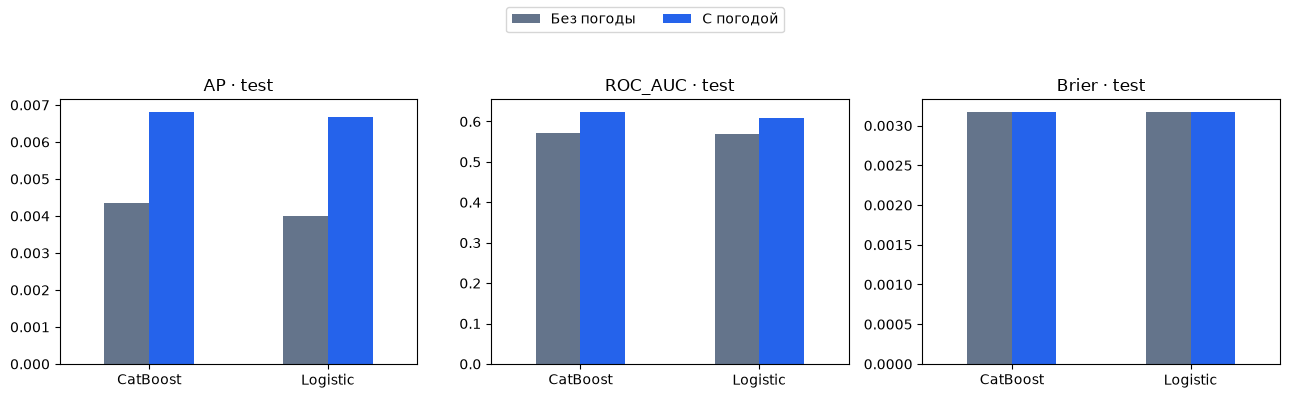

In [5]:
evaluation=experiment.test()
display(evaluation[evaluation.dimension.eq('all')])
comparison=[]
for name in ['baseline','weather']:
    pred=pd.read_parquet(DEST/f'{name}_test_predictions.parquet')
    old=pd.read_parquet(ROOT/f'research/weather-model-comparison/data/primary_models_v1/{name}_test_predictions.parquet').sort_values('source_row').reset_index(drop=True)
    assert pred.drop(columns='probability').equals(old.drop(columns='probability'))
    comparison.extend([{'family':'CatBoost','variant':name,**metrics(pred.GoA,pred.probability)},
                       {'family':'Logistic','variant':name,**metrics(old.GoA,old.probability)}])
comparison=pd.DataFrame(comparison);comparison.to_csv(BASE/'reports/03_family_comparison.csv',index=False);display(comparison)
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,metric in zip(axes,['AP','ROC_AUC','Brier']):
    comparison.pivot(index='family',columns='variant',values=metric).plot.bar(ax=ax,rot=0,color=['#64748b','#2563eb'])
    ax.set_title(metric+' · test');ax.set_xlabel('');ax.get_legend().remove()
handles,_=axes[0].get_legend_handles_labels()
fig.legend(handles,['Без погоды','С погодой'],loc='upper center',ncol=2);fig.tight_layout(rect=(0,0,1,.85))
for ext in ['png','svg']:fig.savefig(BASE/f'figures/03_family_comparison.{ext}',dpi=160,bbox_inches='tight')
plt.show()


## 5. Парные интервалы по UTC-дням

2000 парных повторов, seed=20261011. В обоих вариантах выбираются одни и
те же дни с возвращением. Разность – с погодой минус без погоды.
Для Brier отрицательная разность лучше. Интервалы условны на выбранных
моделях, не включают неопределенность train и не устраняют всю междневную
зависимость. Взвешенные формулы AP/AUC с одинаковыми оценками проверяются
по sklearn перед вычислением интервалов.


In [6]:
a=pd.read_parquet(DEST/'baseline_test_predictions.parquet');b=pd.read_parquet(DEST/'weather_test_predictions.parquet')
assert a.drop(columns='probability').equals(b.drop(columns='probability'))
interval,bootstrap=paired_intervals(a.GoA,a.probability,b.probability,a.C40_CROSS_TIME)
interval.to_csv(BASE/'reports/04_day_intervals.csv',index=False);write_json(BASE/'reports/04_bootstrap_manifest.json',bootstrap)
display(interval);display(bootstrap)


UTC-day bootstrap: 250/2000


UTC-day bootstrap: 500/2000


UTC-day bootstrap: 750/2000


UTC-day bootstrap: 1000/2000


UTC-day bootstrap: 1250/2000


UTC-day bootstrap: 1500/2000


UTC-day bootstrap: 1750/2000


UTC-day bootstrap: 2000/2000


,metric,difference,lower_95,upper_95
0,AP,0.002451,0.001304,0.003992
1,ROC_AUC,0.052536,0.032931,0.073599
2,Brier,-0.000004,-0.000006,-0.000002


{'replicates': 2000,
 'valid': 2000,
 'skipped': 0,
 'days': 148,
 'seed': 20261011,
 'weighted_formulas_checked': True}

## 6. Итоговые проверки и ограничения

Не объявляем систему эксплуатационно пригодной по росту AP. Оцениваем
абсолютную полноту, ложные тревоги и переносимость порогов. Важности признаков
сохранены, но не доказывают причинность. Проверки задержек/COR и независимый
период здесь не добавлены. Новые эксперименты должны иметь отдельный вопрос
и протокол; повторный подбор по просмотренному test не допускается.


In [7]:
saved=[]
for path in sorted(DEST.rglob('*')):
    if path.is_file() and path.suffix in ['.cbm','.parquet','.json'] and 'logs' not in path.parts:
        with path.open('rb') as f: saved.append({'path':path.relative_to(ROOT).as_posix(),'sha256':hashlib.file_digest(f,'sha256').hexdigest()})
write_json(BASE/'reports/05_artifact_manifest.json',{'verified':True,'fingerprint':experiment.fingerprint,'selected':experiment.selected,'candidate_count':10,'test_after_selection':True,'files':saved})
for path in (BASE/'figures').glob('*.svg'):
    path.write_text('\n'.join(line.rstrip() for line in path.read_text(encoding='utf8').splitlines())+'\n',encoding='utf8')
print('Все 10 кандидатов и выбранная пара проверены. Test не использовался для выбора.')


Все 10 кандидатов и выбранная пара проверены. Test не использовался для выбора.
